<p>
<img src="./nlp/imgs/EII-ULPGC-logo.jpeg" width="430px" align="right">

# **Redes neuronales 9**
---

## **Arquitecturas de redes**

Actualmente existe una gran cantidad de modelos de redes neuronales artificiales, pero es interesante estudiar algunos de los que han sido pioneros o destacados, mejorando e introduciendo elementos claves que han supuesto avances significativos.

### **Alexnet**

Esta arquitectura apareció en 2012 y fue una de las primeras redes profundas en mejorar la precisión de la clasificación del conjunto **ImageNet**. Constituyó un gran avance en comparación con los métodos tradicionales. Está compuesta por 5 capas convolutivas seguidas por 3 capas *fully connected*.

<div style="text-align:center">
<img src="imgs/alexnet.png" width="60%">
</div>

AlexNet, propuesta por Alex Krizhevsky, usa ReLU (unidad lineal rectificadora) para la parte no lineal, en lugar de una función tangente hiperbólica o sigmoide, que era el estándar anterior para las redes neuronales tradicionales. La ventaja de la ReLU sobre la sigmoide es que se entrena mucho más rápido que esta última porque la derivada del sigmoide se vuelve muy pequeña en la región de saturación y, por lo tanto, las actualizaciones de los pesos casi desaparecen. Esto se conoce como el problema de **desvanecimiento del gradiente**.

Otro problema que resolvió esta arquitectura fue la reducción del sobreajuste mediante el uso de una capa **dropout** después de cada capa FC.

<div style="text-align:center">
<img src="imgs/dropout.png" width="30%">
</div>

### **VGG16**

Esta arquitectura fue propuesta por el VGG (Visual Geometry Group), Oxford. Lleva a cabo una mejora con respecto a AlexNet al reemplazar los filtros de tamaño (11 y 5 en la primera y segunda capa convolutiva, respectivamente) con múltiples filtros seguidos de tamaño 3X3. Con un campo receptivo dado, el kernel de tamaño más pequeño apilado resulta mejor que el de tamaño más grande porque varias capas no lineales aumentan la profundidad de la red, lo que le permite que extraiga características más complejas a un costo menor.

<div style="text-align: center;">
    <img src="imgs/vgg16.png" width="60%">
</div>

Las capas convolutivas de la VGG16 son seguidas por 3 capas *fully connected*. El número de kernels de la red comienza con un valor de 64 y aumenta en un factor de 2 después de cada capa de *pooling*. Alcanza la precisión del 92.3% en el top-5 en ImageNet.

### **Inception**

GoogLeNet ideó un módulo llamado *Inception* que se aproxima a una CNN dispersa mediante una construcción densa normal. Además, utiliza convoluciones de diferentes tamaños para capturar detalles a escalas variadas (5X5, 3X3, 1X1). Otro punto sobresaliente del módulo es que tiene la llamada capa *bottleneck* (1X1), que ayuda en la reducción masiva de los requisitos de cálculo.

<div style="text-align: center;">
    <img src="imgs/inception-v3-model.png">
    <img src="imgs/inception_module.png">
</div>


### **ResNet**

De acuerdo con lo que hemos visto hasta ahora, aumentar la profundidad debería aumentar la precisión de la red, siempre que se tenga cuidado del sobreajuste. Pero el problema con la mayor profundidad es que la señal requerida para cambiar los pesos, que surge del final de la red al comparar las etiquetas con las predicciones, se vuelve muy pequeña en las capas anteriores, debido a la mayor profundidad. Esencialmente significa que en las capas anteriores el aprendizaje es casi insignificante. Este problema se conoce como **desvanecimiento del gradiente**. El segundo problema con el entrenamiento de las redes más profundas es realizar la optimización en un gran espacio de parámetros. Las redes residuales permiten el desarrollo de redes tan profundas al construir la red a través de módulos llamados **módulos residuales**

<div style="text-align: center;">
    <img src="imgs/residual.png">
</div>

<div style="text-align: center;">
    <img src="imgs/resnet-comp.png">
</div>


### **GAP Global Average Pooling**

En los últimos años se ha recurrido a las capas GAP para minimizar el sobreajuste. Al igual que las capas *maxpooling*, las capas GAP se utilizan para reducir las dimensiones espaciales de un tensor tridimensional. Sin embargo, las capas GAP realizan un tipo más extremo de reducción de dimensionalidad, donde un tensor con dimensiones $h×w×d$ se reduce de tamaño para tener dimensiones $1×1×d$. Las capas GAP reducen cada mapa de características a un solo número simplemente tomando el promedio de todos los valores. En PyTorch, esta capa es <code>nn.AdaptiveAvgPool2d(1)</code>.

<div style="text-align: center;">
    <img src="imgs/gap2.png" width="40%">
</div>

### **Modelos preentrenados en PyTorch**

Todas estas arquitecturas, y muchas más recientes, están disponibles en el módulo <code>torchvision.models</code>, junto con los pesos obtenidos al entrenarlas con *ImageNet*: <code>alexnet</code>, <code>vgg16</code>, <code>inception_v3</code>, <code>resnet50</code>, <code>efficientnet_b0</code>, <code>convnext_tiny</code>, etc. Puedes ver la lista completa y la precisión de cada una en la [documentación de torchvision](https://pytorch.org/vision/stable/models.html).

## **Transfer Learning**

La **transferencia del aprendizaje** (*transfer learning*) es un método muy usado para la construcción de modelos de redes neuronales. Suele dar buenos resultados y se usa, principalmente, cuando no tenemos muchas muestras en nuestro *dataset* de entrenamiento.

La idea es la siguiente: una red entrenada con millones de imágenes, como las de *ImageNet*, ya ha aprendido en sus capas convolutivas a extraer características muy útiles (bordes, texturas, formas, partes de objetos…) que sirven para casi cualquier problema de visión. Así que, en lugar de empezar desde cero, tomamos esas capas convolutivas ya entrenadas, **congelamos sus pesos** y les conectamos una nueva parte final *fully connected* que lleve a cabo nuestra tarea de clasificación. Los únicos pesos que se modifican durante el entrenamiento serán los de esa parte final.

Para empezar a estudiar esta técnica, comenzaremos cargando y usando un modelo VGG16 de los que incluye **torchvision**. Las siguientes líneas cargan el modelo junto con el conjunto de pesos de la red entrenada con el *dataset* *ImageNet*. La primera vez que se ejecuten se descargarán los pesos (unos 530 MB), que quedarán guardados en una caché para las siguientes ocasiones.

Además de los pesos, el objeto <code>weights</code> nos proporciona dos cosas muy útiles:

- <code>weights.transforms()</code>: el **preprocesado exacto** que hay que aplicar a una imagen antes de pasarla por la red (redimensionarla, recortarla a $224\times224$ y normalizar cada canal con la media y la desviación típica de *ImageNet*). Si no preprocesamos las imágenes igual que en el entrenamiento original, la red funcionará mal.
- <code>weights.meta["categories"]</code>: los nombres de las 1000 categorías de *ImageNet*.

In [1]:
import torch
from torch import nn
from torchvision.models import vgg16, VGG16_Weights

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Usando:", device)

weights = VGG16_Weights.IMAGENET1K_V1
model = vgg16(weights=weights).to(device)
model.eval()  # Modo evaluación: desactiva el dropout de las capas fully connected

preprocess = weights.transforms()
categories = weights.meta["categories"]

print(model)

Usando: mps
VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0

Fíjate en la estructura que muestra PyTorch. El modelo tiene tres partes: <code>features</code>, con las 13 capas convolutivas y las de *maxpooling*; <code>avgpool</code>; y <code>classifier</code>, con las 3 capas *fully connected*. Esta separación nos vendrá muy bien para hacer *transfer learning*.

Este modelo tiene 1000 salidas correspondientes a las 1000 categorías en las que clasifica. Hay categorías muy diversas, como "casetes musicales" o "trilobites prehistóricos". Échale un vistazo a todas las que hay.

In [2]:
print(len(categories), "categorías\n")
for i in range(0, 1000, 4):
    print("  ".join(f"{j:3d} {categories[j][:24]:<24}" for j in range(i, i + 4)))

1000 categorías

  0 tench                       1 goldfish                    2 great white shark           3 tiger shark             
  4 hammerhead                  5 electric ray                6 stingray                    7 cock                    
  8 hen                         9 ostrich                    10 brambling                  11 goldfinch               
 12 house finch                13 junco                      14 indigo bunting             15 robin                   
 16 bulbul                     17 jay                        18 magpie                     19 chickadee               
 20 water ouzel                21 kite                       22 bald eagle                 23 vulture                 
 24 great grey owl             25 European fire salamander   26 common newt                27 eft                     
 28 spotted salamander         29 axolotl                    30 bullfrog                   31 tree frog               
 32 tailed frog                

He descargado un par de imágenes de internet y las he pasado por la red. A ver qué sale...

Observa los pasos: abrimos la imagen, le aplicamos el preprocesado, le añadimos la dimensión del lote con <code>unsqueeze(0)</code> (la red espera un lote de imágenes, no una sola) y, como la red devuelve *logits*, aplicamos <code>softmax</code> para obtener probabilidades.

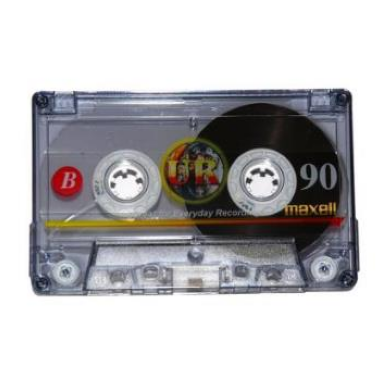

cassette              94.70 %
tape player            3.94 %
cassette player        1.08 %
hard disc              0.16 %
CD player              0.05 %


In [3]:
from PIL import Image
import matplotlib.pyplot as plt

# img_path = 'imgs/trilobite.jpeg'
img_path = 'imgs/cassete.jpeg'

img = Image.open(img_path).convert('RGB')
plt.imshow(img)
plt.axis('off')
plt.show()

x = preprocess(img).unsqueeze(0).to(device)  # (1, 3, 224, 224)

with torch.no_grad():
    probs = torch.softmax(model(x), dim=1)[0]

top5 = torch.topk(probs, 5)
for p, idx in zip(top5.values, top5.indices):
    print(f"{categories[idx]:<20} {100 * p:6.2f} %")

Vemos que, efectivamente, nos devuelve la categoría "cassette" con una probabilidad muy alta.

### **Nuestro modelo tradicional**

Para poder comparar los resultados usando **transfer learning** crearemos primero un modelo con capas convolutivas y *fully connected* como hemos hecho hasta ahora. El *dataset* que vamos a utilizar se compone de imágenes de perros y gatos (por ejemplo, el *dataset* [Cat and Dog](https://www.kaggle.com/datasets/tongpython/cat-and-dog) de Kaggle), organizadas en la carpeta <code>data/dogs_vs_cats/training_set</code> con una subcarpeta por clase (<code>cats</code> y <code>dogs</code>). Por tanto, será un clasificador **binario**.

Para preparar los datos usamos <code>ImageFolder</code>, como en la clase 7, y separamos el 20% de las imágenes para validación. Las imágenes se preprocesan igual que para la VGG16: redimensionadas a $224\times224$ y normalizadas con la media y la desviación típica de *ImageNet*. Así podremos usar los mismos datos para los dos modelos.

In [6]:
# DATA SOURCE --------------------------------------------------

from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader, random_split

image_size = (224, 224)
batch_size = 32

transform = v2.Compose([
    v2.Resize(image_size),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Media y desviación de ImageNet
])

dataset = datasets.ImageFolder("data/dogs_vs_cats/training_set", transform=transform)
print(f"Found {len(dataset)} files belonging to {len(dataset.classes)} classes: {dataset.classes}")

n_val = int(0.2 * len(dataset))
train_set, val_set = random_split(dataset, [len(dataset) - n_val, n_val], generator=torch.Generator().manual_seed(1337))
print(f"Using {len(train_set)} files for training and {len(val_set)} for validation.")

# num_workers > 0 carga y preprocesa las imágenes en paralelo mientras la red entrena
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=batch_size, num_workers=2)

Found 8005 files belonging to 2 classes: ['cats', 'dogs']
Using 6404 files for training and 1601 for validation.


Como vamos a entrenar dos modelos, escribimos una sola vez las funciones de entrenamiento y evaluación. Al ser un problema binario, la red tendrá **una sola salida** y usaremos <code>nn.BCEWithLogitsLoss</code>, que aplica internamente la sigmoide (por eso la última capa no la lleva). Una imagen se clasifica como perro si la salida es mayor que 0, es decir, si la probabilidad es mayor que 0.5.

La función <code>fit</code> incluye el *early stopping* que vimos en la clase 7: si la precisión de validación no mejora durante <code>patience</code> épocas, se detiene el entrenamiento y se recuperan los mejores pesos.

In [8]:
import copy
from time import time

loss_fn = nn.BCEWithLogitsLoss()


def run_epoch(model, loader, optimizer=None):
    # Entrena una época si se le pasa un optimizador; si no, solo evalúa
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.float().unsqueeze(1).to(device)
            logits = model(x)
            loss = loss_fn(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(x)
            correct += ((logits > 0).float() == y).sum().item()
            n += len(x)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, patience=3):
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_acc, best_weights, waiting = -1.0, None, 0
    for epoch in range(epochs):
        t0 = time()
        loss, acc = run_epoch(model, train_loader, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader)
        for k, v in zip(history, (loss, acc, val_loss, val_acc)):
            history[k].append(v)
        print(f"Época {epoch + 1}/{epochs} - {time() - t0:.0f}s - loss: {loss:.4f} - accuracy: {acc:.4f}"
              f" - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")
        if val_acc > best_acc:
            best_acc, best_weights, waiting = val_acc, copy.deepcopy(model.state_dict()), 0
        else:
            waiting += 1
            if waiting >= patience:
                print("Early stopping")
                break
    model.load_state_dict(best_weights)
    return history


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    fmt = lambda n: f"{n:,}".replace(",", ".")
    print(f"Parámetros: {fmt(total)} en total, {fmt(trainable)} entrenables")

In [9]:
# MODEL --------------------------------------------------

torch.manual_seed(0)

cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3),    # 3x224x224   -> 32x222x222
    nn.ReLU(),
    nn.MaxPool2d(2),                    # -> 32x111x111
    nn.Conv2d(32, 64, kernel_size=3),   # -> 64x109x109
    nn.ReLU(),
    nn.MaxPool2d(2),                    # -> 64x54x54
    nn.Dropout(0.25),
    nn.Conv2d(64, 128, kernel_size=3),  # -> 128x52x52
    nn.ReLU(),
    nn.MaxPool2d(2),                    # -> 128x26x26
    nn.Dropout(0.25),
    nn.Flatten(),                       # -> 86528
    nn.Linear(128 * 26 * 26, 128),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(128, 1)                   # Una salida, sin sigmoide (la aplica BCEWithLogitsLoss)
).to(device)

count_parameters(cnn)

Parámetros: 11.169.089 en total, 11.169.089 entrenables


In [10]:
# TRAINING --------------------------------------------------

optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)
h = fit(cnn, optimizer, epochs=10, patience=10)

Época 1/10 - 48s - loss: 0.6837 - accuracy: 0.5539 - val_loss: 0.6454 - val_accuracy: 0.6084
Época 2/10 - 41s - loss: 0.6189 - accuracy: 0.6473 - val_loss: 0.5853 - val_accuracy: 0.6615
Época 3/10 - 41s - loss: 0.5223 - accuracy: 0.7420 - val_loss: 0.5488 - val_accuracy: 0.7171
Época 4/10 - 42s - loss: 0.4570 - accuracy: 0.7804 - val_loss: 0.4699 - val_accuracy: 0.7833
Época 5/10 - 42s - loss: 0.3967 - accuracy: 0.8186 - val_loss: 0.5011 - val_accuracy: 0.7601
Época 6/10 - 42s - loss: 0.3416 - accuracy: 0.8521 - val_loss: 0.4569 - val_accuracy: 0.7901
Época 7/10 - 42s - loss: 0.2707 - accuracy: 0.8882 - val_loss: 0.4968 - val_accuracy: 0.7833
Época 8/10 - 41s - loss: 0.2034 - accuracy: 0.9204 - val_loss: 0.5317 - val_accuracy: 0.7951
Época 9/10 - 43s - loss: 0.1654 - accuracy: 0.9360 - val_loss: 0.4995 - val_accuracy: 0.7845
Época 10/10 - 42s - loss: 0.1279 - accuracy: 0.9516 - val_loss: 0.6752 - val_accuracy: 0.7758


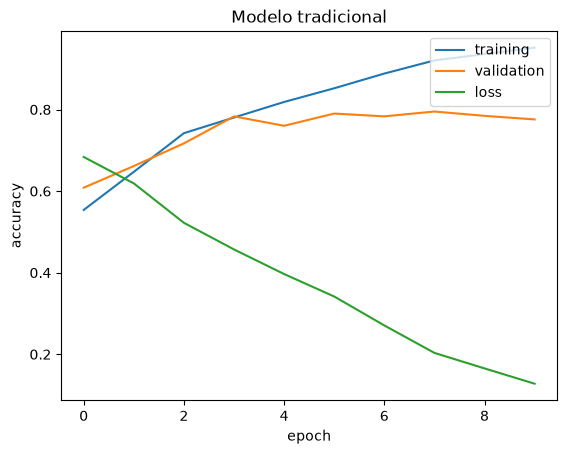

In [11]:
def plot_history(h, title):
    plt.plot(h['accuracy'], label='training')
    plt.plot(h['val_accuracy'], label='validation')
    plt.plot(h['loss'], label='loss')
    plt.title(title)
    plt.ylabel('accuracy')
    plt.xlabel('epoch')
    plt.legend(loc='upper right')
    plt.show()

plot_history(h, 'Modelo tradicional')

### **Transfer learning con VGG16**

Ahora cargaremos el modelo de la red VGG16, pero solo su parte convolutiva (<code>features</code>), con los pesos con los que se entrenó con el *dataset* *ImageNet*. Para **congelar** sus pesos basta con indicar que no necesitan gradiente (<code>requires_grad = False</code>): así, durante la retropropagación, PyTorch no los modificará.

La salida de <code>features</code> es un tensor de $512\times7\times7$. En lugar de aplanarlo, lo reducimos a un vector de 512 valores con una capa de **Global Average Pooling** (<code>nn.AdaptiveAvgPool2d(1)</code>), y a continuación añadimos nuestra parte *fully connected*: una capa oculta de 256 neuronas y una salida.

In [12]:
base_model = vgg16(weights=VGG16_Weights.IMAGENET1K_V1).features

for p in base_model.parameters():
    p.requires_grad = False  # Congelamos la parte convolutiva

torch.manual_seed(0)

tl_model = nn.Sequential(
    base_model,                # 3x224x224 -> 512x7x7
    nn.AdaptiveAvgPool2d(1),   # Global Average Pooling -> 512x1x1
    nn.Flatten(),              # -> 512
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 1)
).to(device)

count_parameters(tl_model)

Parámetros: 14.846.273 en total, 131.585 entrenables


Observa la diferencia: de los casi 15 millones de parámetros del modelo, solo unos 130.000 son entrenables. Al optimizador le pasamos únicamente esos parámetros.

Con una sola época de entrenamiento ya suele obtenerse una precisión de validación muy superior a la del modelo tradicional tras 10 épocas. Eso sí, cada época es más lenta: aunque no se entrenen, las 13 capas convolutivas de VGG16 tienen que procesar todas las imágenes. Aquí es donde una GPU marca la diferencia.

In [13]:
trainable = [p for p in tl_model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(trainable, lr=1e-3)

h_tl = fit(tl_model, optimizer, epochs=3, patience=3)

Época 1/3 - 84s - loss: 0.0735 - accuracy: 0.9703 - val_loss: 0.0350 - val_accuracy: 0.9881
Época 2/3 - 82s - loss: 0.0340 - accuracy: 0.9869 - val_loss: 0.0323 - val_accuracy: 0.9900
Época 3/3 - 82s - loss: 0.0284 - accuracy: 0.9889 - val_loss: 0.0425 - val_accuracy: 0.9850


### **Fine-tuning**

Una vez entrenada la parte final, todavía podemos mejorar un poco más con la técnica del **ajuste fino** (*fine-tuning*): descongelamos las últimas capas convolutivas de la red base y seguimos entrenando todo el conjunto con una **tasa de aprendizaje muy pequeña**. Así, las características más abstractas de VGG16 se adaptan ligeramente a nuestro problema sin destruir lo que ya habían aprendido.

Es importante hacerlo en este orden. Si descongeláramos desde el principio, los gradientes grandes que produce una parte final todavía sin entrenar estropearían los pesos preentrenados.

En VGG16, el último bloque convolutivo corresponde a las capas <code>features[24:]</code> (tres convoluciones y un *maxpooling*).

In [14]:
for p in base_model[24:].parameters():
    p.requires_grad = True  # Descongelamos el último bloque convolutivo

count_parameters(tl_model)

trainable = [p for p in tl_model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(trainable, lr=1e-5)  # Tasa de aprendizaje muy pequeña

h_ft = fit(tl_model, optimizer, epochs=2, patience=2)

Parámetros: 14.846.273 en total, 7.211.009 entrenables
Época 1/2 - 94s - loss: 0.0227 - accuracy: 0.9909 - val_loss: 0.0299 - val_accuracy: 0.9900
Época 2/2 - 95s - loss: 0.0096 - accuracy: 0.9978 - val_loss: 0.0343 - val_accuracy: 0.9906


## **Ejercicios**

- Compara en una misma gráfica la evolución del *accuracy* de validación del modelo tradicional y del modelo con *transfer learning*.


- Como la parte convolutiva de VGG16 está congelada, en cada época se calculan una y otra vez exactamente las mismas características para las mismas imágenes. Haz que el entrenamiento sea mucho más rápido calculando una sola vez la salida de <code>base_model</code> para todas las imágenes, guardándola en un tensor y entrenando la parte *fully connected* sobre esas características.


- Sustituye VGG16 por otra red preentrenada de <code>torchvision.models</code>, por ejemplo <code>resnet18</code> o <code>efficientnet_b0</code>. Pista: en ResNet la última capa se llama <code>fc</code>, y puedes sustituirla directamente por la tuya: <code>model.fc = nn.Linear(512, 1)</code>.


- Añade *data augmentation* al conjunto de entrenamiento y comprueba si mejora el modelo tradicional.